In [1]:
!pip install pmdarima

In [2]:
# Setup and Library Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Statsmodels for modeling
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

# Pmdarima for automatic identification (auto_arima)
import pmdarima as pm

# Metrics for comparison
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

# Plot configuration
plt.style.use('seaborn-v0_8-darkgrid' if 'seaborn-v0_8-darkgrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (16, 7)
plt.rcParams['font.size'] = 12

np.random.seed(101) # For reproducibility

## Theory: The ARIMA Family of Models

### **The ARMA(p, q) Components**
An **ARMA** (Autoregressive Moving Average) process describes a stationary series $Y_t$ by combining two temporal dependence structures:

1.  **Autoregressive Component AR(p):** We model $Y_t$ as a linear combination of its $p$ past values ($Y_{t-1}, \dots, Y_{t-p}$). It represents inertia or the "memory of levels".
    $$ Y_t = \alpha + \phi_1 Y_{t-1} + \dots + \phi_p Y_{t-p} + \epsilon_t $$
    where $\epsilon_t \sim WN(0, \sigma^2)$ is the White Noise (innovation).

2.  **Moving Average Component MA(q):** We model $Y_t$ as a linear combination of $q$ past random shocks ($\epsilon_{t-1}, \dots, \epsilon_{t-q}$). It represents the persistence of forecast errors.
    $$ Y_t = \mu + \epsilon_t + \theta_1 \epsilon_{t-1} + \dots + \theta_q \epsilon_{t-q} $$

### **Integration: ARIMA(p, d, q) Models**
In real applications, the original series $X_t$ is rarely stationary ($I(1)$ or higher). We must apply the difference operator $\nabla$ $d$ times to obtain a stationary series $Y_t = \nabla^d X_t$.

An **ARIMA** (AutoRegressive Integrated Moving Average) model is simply an ARMA(p, q) model applied to the series differenced $d$ times.
The model orders are:
*   $p$: Order of the Autoregressive part (how many level lags).
*   $d$: Order of Integration (how many times we differenced).
*   $q$: Order of the Moving Average part (how many error lags).

---

## The Box-Jenkins Methodology

In 1970, George Box and Gwilym Jenkins formalized an iterative workflow for ARIMA modeling, divided into 4 steps:

### **Identification and Preprocessing**
1.  **Stabilize the Variance:** Use transformations (e.g. Log) if the series is heteroskedastic.
2.  **Stationarity in Mean ($d$):** Visual analysis and ADF Test. Difference ($\nabla$) until the series is stationary. Determine $d$.
3.  **AR/MA Orders ($p, q$):** Analysis of the **ACF** and **PACF** correlograms on the stationary series.
    *   Sharp PACF cut-off $\implies$ Suggests AR order $p$.
    *   Sharp ACF cut-off $\implies$ Suggests MA order $q$.

### **Parameter Estimation**
Use of algorithms (Maximum Likelihood - MLE) to numerically compute the optimal coefficients $\phi_i$ and $\theta_i$ that minimize the model error.

### **Residual Diagnostics**
The model is valid only if the residuals $\hat{\epsilon}_t$ are **White Noise** (no residual information).
1.  **Zero Mean:** Visual check.
2.  **Homoskedasticity:** Constant residual variance.
3.  **No Autocorrelation:** The residual ACF must be zero for all lags $>0$. Formal check via the **Ljung-Box Test**.

### **Forecasting**
Use of the validated model to generate out-of-sample forecasts with their confidence intervals.

Total Dataset: 144 observations.
Training set: 122 observations (1949 - 1959).
Test set: 22 observations (1959 - 1960).


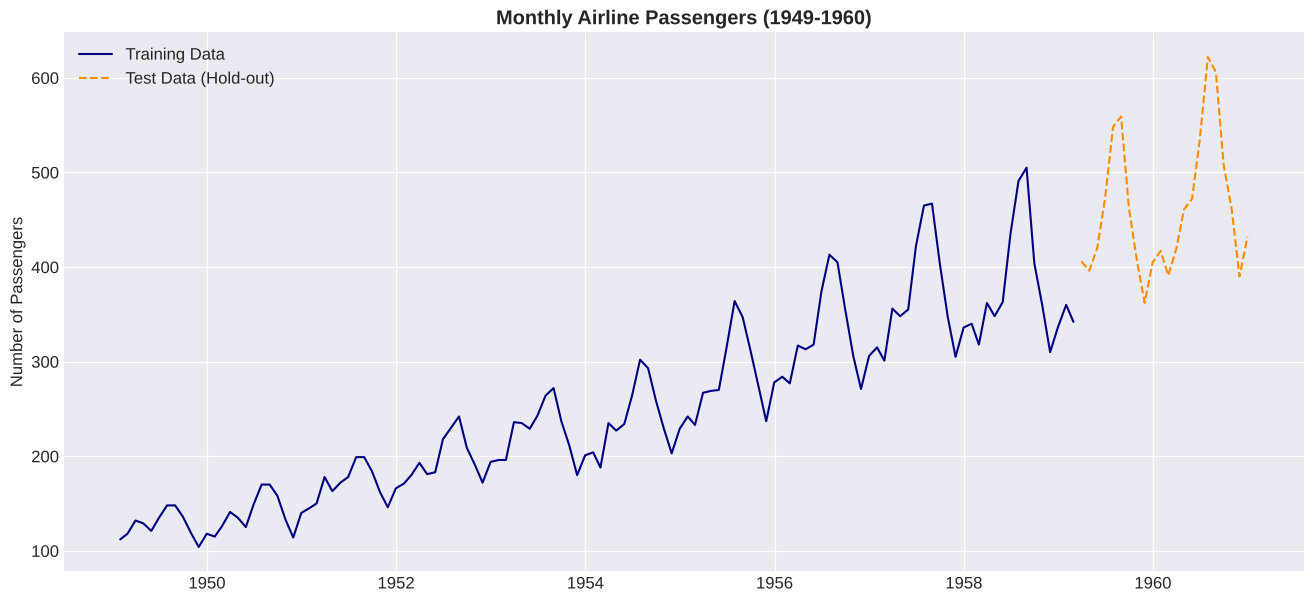

In [3]:
# Implementation of the Box-Jenkins Workflow on a Real Dataset

# We use a classic dataset: monthly airline passengers (AirPassengers)
# It is a well-known dataset with a non-stationary trend and growing seasonality.
# statsmodels provides it directly.

from statsmodels.datasets import get_rdataset
data = get_rdataset("AirPassengers", cache=True).data
data.index = pd.date_range(start='1949-01-01', periods=len(data), freq='ME')
ts = data['value']

# Create train and test sets (chronological split) for the final forecasting
train_size = int(len(ts) * 0.85)
train, test = ts[0:train_size], ts[train_size:len(ts)]

print(f"Total Dataset: {len(ts)} observations.")
print(f"Training set: {len(train)} observations (1949 - {train.index[-1].year}).")
print(f"Test set: {len(test)} observations ({test.index[0].year} - 1960).")

# Plot the original series
plt.figure()
plt.plot(train, label='Training Data', color='navy')
plt.plot(test, label='Test Data (Hold-out)', color='darkorange', linestyle='--')
plt.title("Monthly Airline Passengers (1949-1960)", fontweight='bold')
plt.ylabel("Number of Passengers")
plt.legend()
plt.show()

## Identification and Preprocessing

### **Variance Stabilization (Log-Transform)**
From the plot we observe that the amplitude of the seasonality grows linearly with the level of the series (heteroskedasticity). We apply the logarithmic transformation ($\ln$) to stabilize it.

In [4]:
# Log transformation
train_log = np.log(train)

# Helper function for the ADF test
def adf_test(series, title=""):
    print(f'--- ADF Test: {title} ---')
    result = adfuller(series, autolag='AIC')
    print(f'ADF Statistic: {result[0]:.4f}')
    print(f'p-value: {result[1]:.2e}')
    if result[1] <= 0.05:
        print("Result: Stationary (Reject H0)\n")
        return True
    else:
        print("Result: Non-Stationary (Fail to reject H0)\n")
        return False

# Stationarity in Mean Analysis (ADF Test)
adf_test(train_log, title="Log Series (Levels)")

# The log series is not stationary (high p-value). We apply the difference operator (nabla).

--- ADF Test: Log Series (Levels) ---
ADF Statistic: -1.8252
p-value: 3.68e-01
Result: Non-Stationary (Fail to reject H0)



/tmp/ipykernel_529/1977382004.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, autolag='AIC')


False

--- ADF Test: Log Series + Diff (d=1) ---
ADF Statistic: -2.6167
p-value: 8.96e-02
Result: Non-Stationary (Fail to reject H0)



/tmp/ipykernel_529/1977382004.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, autolag='AIC')


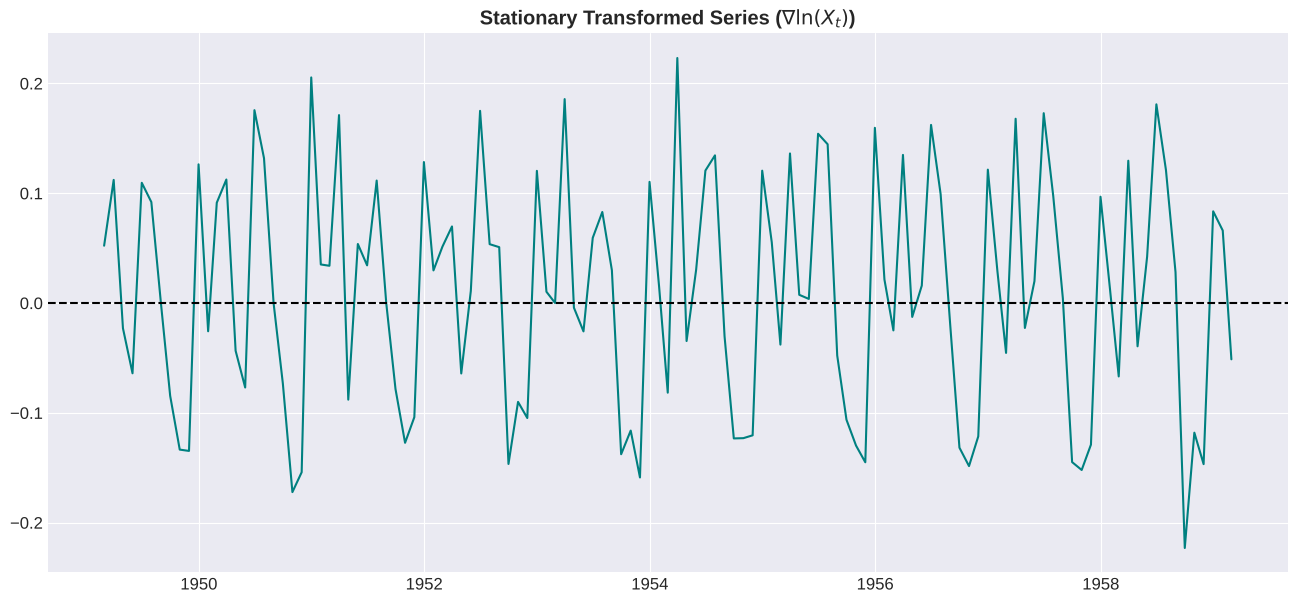

In [5]:
# Differencing d=1
train_log_diff = train_log.diff().dropna()

# ADF test on the differenced series
is_stationary = adf_test(train_log_diff, title="Log Series + Diff (d=1)")

# Plot the stationary differenced series
plt.figure()
plt.plot(train_log_diff, color='teal')
plt.axhline(0, color='black', linestyle='--')
plt.title(r"Stationary Transformed Series ($\nabla \ln(X_t)$)", fontweight='bold')
plt.show()

# We determined d = 1.

### **Identifying the AR(p) and MA(q) Orders**
Now that the series is stationary in mean (I(0)), we analyze the **ACF** (for $q$) and **PACF** (for $p$) autocorrelation functions.

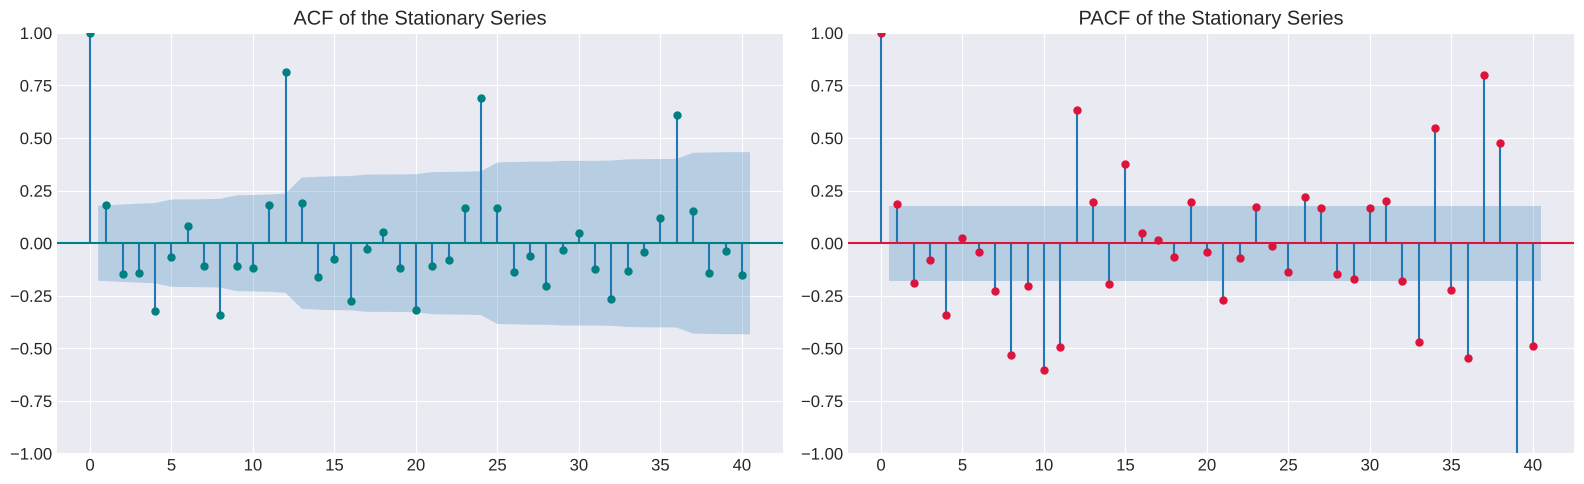

In [6]:
# ACF and PACF analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# ACF -> Identification of q (MA)
# Note: The ACF shows significant spikes at lags 1, 2 and then at 12 (seasonality). 
# An MA(1) or MA(2) model might be adequate for the non-seasonal part.
plot_acf(train_log_diff, lags=40, ax=axes[0], color='teal', title="ACF of the Stationary Series")

# PACF -> Identification of p (AR)
# Note: The PACF shows a very sharp spike at lag 1, then drops. It suggests AR(1).
# Uses 'yw' for Yule-Walker
plot_pacf(train_log_diff, lags=40, ax=axes[1], color='crimson', title="PACF of the Stationary Series", method='yw')

plt.tight_layout()
plt.show()

# MODEL HYPOTHESIS: ARIMA(1, 1, 1)
# We choose p=1 (from the PACF), d=1 (differencing done), q=1 (from the ACF, parsimonious choice).

## Estimation and Residual Diagnostics

We estimate the **ARIMA(1, 1, 1)** model and immediately proceed to the diagnostic check of the residuals.

                               SARIMAX Results                                
Dep. Variable:                  value   No. Observations:                  122
Model:                 ARIMA(1, 1, 1)   Log Likelihood                 106.582
Date:                Mon, 05 Oct 2026   AIC                           -207.163
Time:                        20:47:22   BIC                           -198.776
Sample:                    01-31-1949   HQIC                          -203.757
                         - 02-28-1959                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5766      0.186     -3.094      0.002      -0.942      -0.211
ma.L1          0.8366      0.113      7.382      0.000       0.614       1.059
sigma2         0.0100      0.002      5.690      0.0

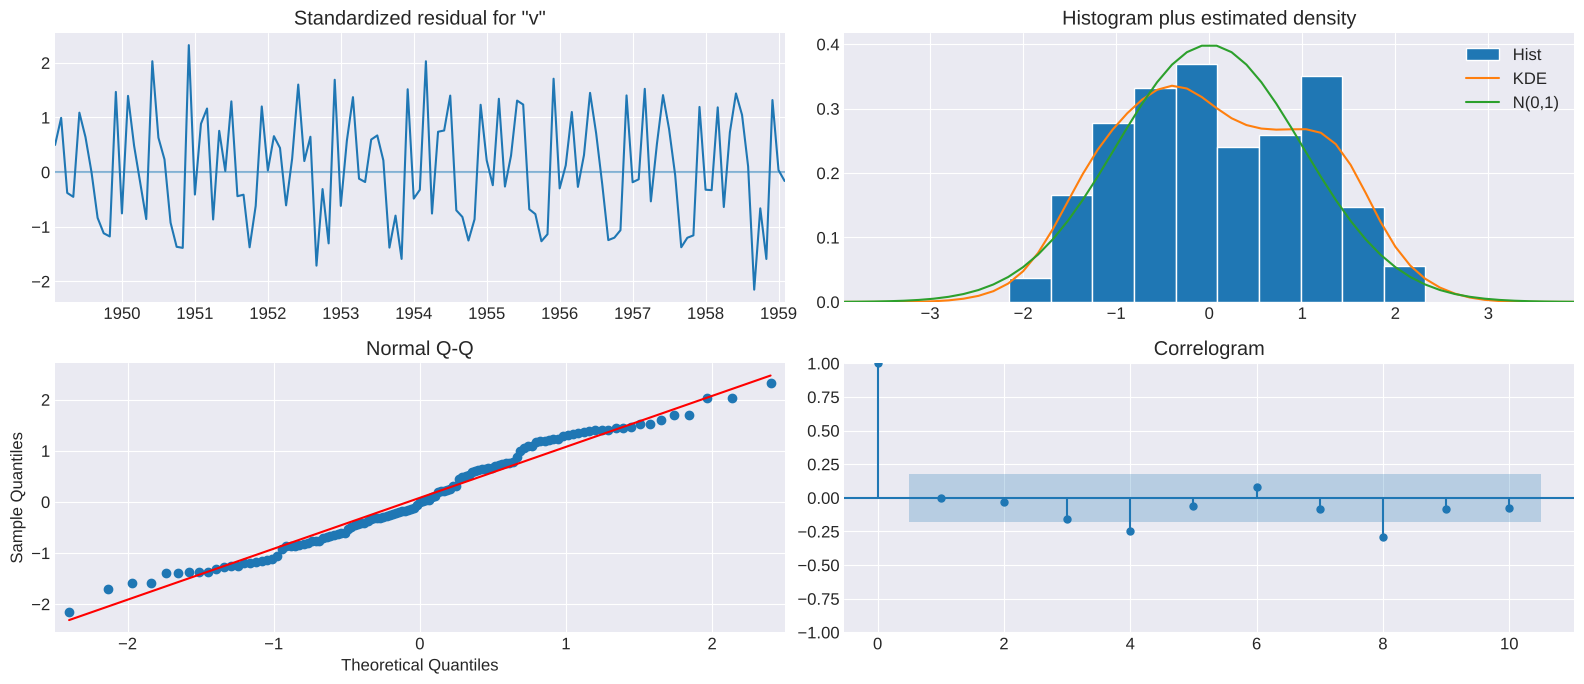

In [7]:
# Estimation of the manual ARIMA(1, 1, 1) model
# Note: We apply the ARIMA model to the LOG series, specifying d=1 in the model.
# Statsmodels handles the differencing internally.
manual_model = ARIMA(train_log, order=(1, 1, 1))
manual_results = manual_model.fit()

# Show the full summary
print(manual_results.summary())

# Residual Diagnostics
# Statsmodels provides a powerful automatic diagnostic plot
manual_results.plot_diagnostics()
plt.tight_layout()
plt.show()

### Interpreting the Diagnostics (White Noise Test)

1.  **Standardized Residuals:** The residuals fluctuate around zero with no apparent trend and fairly constant variance.
2.  **Histogram + KDE:** The distribution of the residuals (histogram) is close to a Standard Normal $\mathcal{N}(0, 1)$ (green line), although with slightly heavy tails.
3.  **Normal Q-Q Plot:** The points follow the red 45-degree line, confirming near-normality.
4.  **Correlogram (residual ACF):** All spikes (except lag 0) are **inside the confidence bands**. This strongly suggests that the residuals are **uncorrelated** (White Noise).

---

## Forecasting and Advanced Comparison

Now we generate the forecasts of our manual model on the test set (hold-out data). We also introduce a comparison with the automated approach: `auto_arima` from the `pmdarima` library.

`auto_arima` runs an exhaustive search (grid-search) over many combinations of $(p, d, q)$ and picks the one that minimizes an information criterion (AIC or BIC), balancing goodness of fit and parsimony (Ep. 4 theory).

In [8]:
# Out-of-Sample Forecasting (Manual Model)
# Generate forecasts for the length of the test set
forecast_manual = manual_results.get_forecast(steps=len(test))
forecast_manual_conf = forecast_manual.conf_int() # Confidence intervals

# We must back-transform the log values to the original scale (exponential)
fc_manual_series = np.exp(forecast_manual.predicted_mean)
fc_manual_lower = np.exp(forecast_manual_conf.iloc[:, 0])
fc_manual_upper = np.exp(forecast_manual_conf.iloc[:, 1])

# Automatic approach with auto_arima (Comparison)
# auto_arima receives the log-transformed series; it handles d internally.
print("\n--- Starting auto_arima Grid Search ---")
auto_model_fit = pm.auto_arima(train_log,
                               start_p=0, start_q=0, max_p=3, max_q=3,
                               d=None,           # Let auto_arima choose d
                               seasonal=False,   # Ignore seasonality for simplicity in this video
                               trace=True,       # Show the models tried
                               error_action='ignore',
                               suppress_warnings=True,
                               stepwise=True)    # Fast search algorithm

print(f"\nOptimal model automatically selected (AIC minimization): {auto_model_fit.order}")
print(auto_model_fit.summary())

# Out-of-Sample Forecasting (Automatic Model)
forecast_auto, forecast_auto_conf = auto_model_fit.predict(n_periods=len(test), return_conf_int=True)
fc_auto_series = np.exp(forecast_auto)
# Handle confidence intervals for pmdarima (numpy array)
fc_auto_lower = np.exp(forecast_auto_conf[:, 0])
fc_auto_upper = np.exp(forecast_auto_conf[:, 1])


--- Starting auto_arima Grid Search ---
Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-198.496, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-200.603, Time=0.02 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-202.454, Time=0.02 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=-199.562, Time=0.02 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=-205.947, Time=0.05 sec


 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.10 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=0.13 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=-205.957, Time=0.04 sec


 ARIMA(0,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=0.10 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=-221.005, Time=0.13 sec


 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=0.18 sec
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-221.680, Time=0.13 sec


 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=-225.967, Time=0.13 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=-225.629, Time=0.12 sec


 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=0.15 sec
 ARIMA(3,1,2)(0,0,0)[0]             : AIC=-212.990, Time=0.09 sec

Best model:  ARIMA(3,1,2)(0,0,0)[0] intercept
Total fit time: 1.465 seconds

Optimal model automatically selected (AIC minimization): (3, 1, 2)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  122
Model:               SARIMAX(3, 1, 2)   Log Likelihood                 119.984
Date:                Mon, 05 Oct 2026   AIC                           -225.967
Time:                        20:47:24   BIC                           -206.397
Sample:                    01-31-1949   HQIC                          -218.019
                         - 02-28-1959                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
-----------------

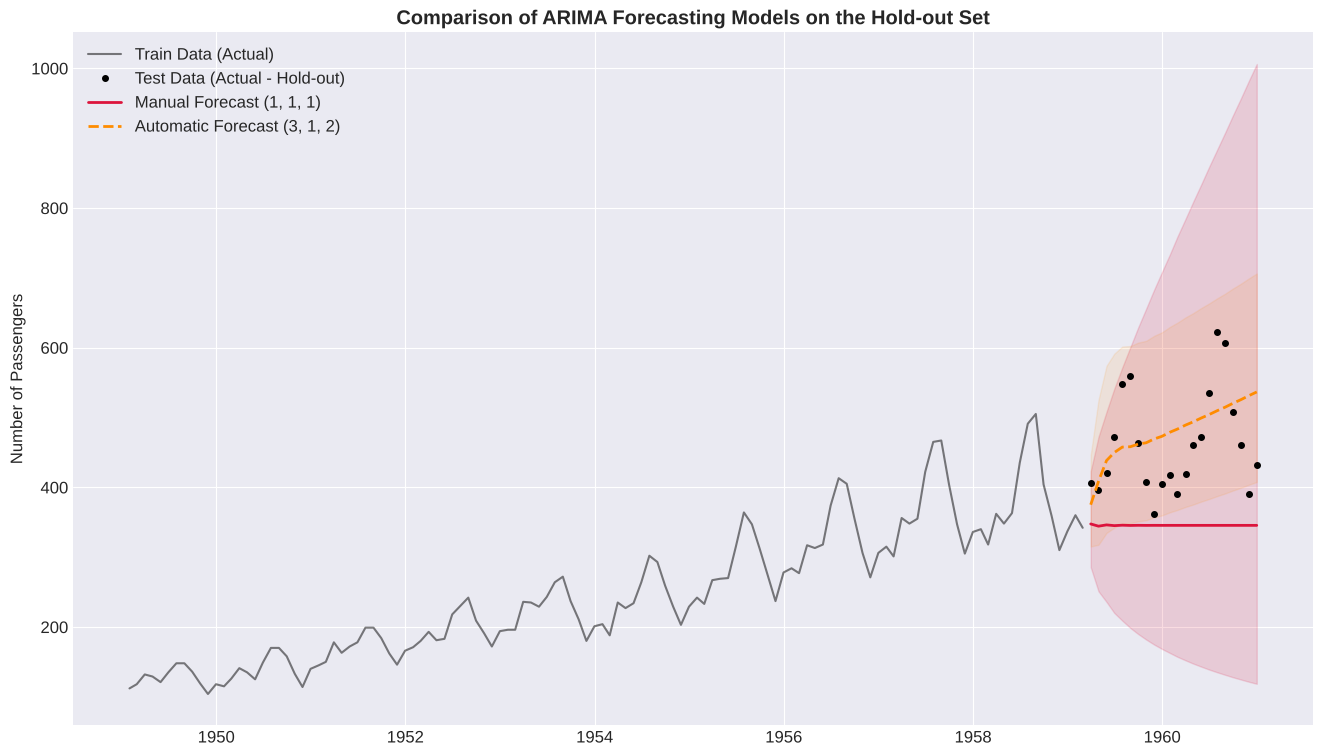

   COMPARISON RESULTS (MAPE - Percentage Error)
Manual Model ARIMA(1, 1, 1): MAPE = 23.47%
Automatic Model (3, 1, 2): MAPE = 13.58%


In [9]:
# Final Visualization and Performance Comparison

plt.figure(figsize=(16, 9))

# Real Data
plt.plot(train, label='Train Data (Actual)', color='black', alpha=0.5)
plt.plot(test, label='Test Data (Actual - Hold-out)', color='black', marker='o', markersize=4, linestyle='None')

# Manual ARIMA(1, 1, 1) Forecasts
plt.plot(test.index, fc_manual_series, label='Manual Forecast (1, 1, 1)', color='crimson', linewidth=2)
plt.fill_between(test.index, fc_manual_lower, fc_manual_upper, color='crimson', alpha=0.15)

# Automatic Forecasts
auto_order_label = f"Automatic Forecast {auto_model_fit.order}"
plt.plot(test.index, fc_auto_series, label=auto_order_label, color='darkorange', linewidth=2, linestyle='--')
plt.fill_between(test.index, fc_auto_lower, fc_auto_upper, color='darkorange', alpha=0.1)

plt.title("Comparison of ARIMA Forecasting Models on the Hold-out Set", fontweight='bold')
plt.ylabel("Number of Passengers")
plt.legend(loc='upper left')
plt.show()

# Compute error metrics (MAPE works well for series with a trend)
mape_manual = mean_absolute_percentage_error(test, fc_manual_series)
mape_auto = mean_absolute_percentage_error(test, fc_auto_series)

print(f"==================================================")
print(f"   COMPARISON RESULTS (MAPE - Percentage Error)")
print(f"==================================================")
print(f"Manual Model ARIMA(1, 1, 1): MAPE = {mape_manual:.2%}")
print(f"Automatic Model {auto_model_fit.order}: MAPE = {mape_auto:.2%}")
print(f"==================================================")